In [1]:
# Make the project importable whether this runs from notebooks/ or the repo root.
import pathlib
import sys

_root = next(
    p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    if (p / "src" / "__init__.py").exists()
)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

# 06 · Decision Framework

**Do you even need one?** You have now built the two things a feature store gives you and seen
them in Feast. The honest conclusion for many projects is: you do not need the *tool*. But you
always need the two *disciplines*. This notebook states when to reach for what — and the rule
that outranks the tool choice.

In [2]:
from src.artifacts import apply_style, save_figure, save_json, BLUE, ORANGE, AQUA, TEXT_PRIMARY, TEXT_SECONDARY, GRID
from src.config import settings
from src.datasets.events import load
from src.evaluation.comparison import run_all
from src.evaluation.leakage import run_leakage_experiment
from src.evaluation.skew import run_skew_experiment
import matplotlib.pyplot as plt
import numpy as np

apply_style()
ds = load(settings)
summary = run_all(ds, settings)
summary

,experiment,metric,value
0,leakage,naive offline AUC,0.864482
1,leakage,honest offline AUC,0.723892
2,leakage,naive future AUC,0.712111
3,leakage,honest future AUC,0.712111
4,leakage,inflation (naive-honest offline),0.140590
5,leakage,collapse (naive offline-future),0.152372
6,skew,feature disagreement rate,0.962000
7,skew,mean abs feature diff,6.711000
8,skew,correct-feature AUC,0.723898
9,skew,divergent-feature AUC,0.703846


## The decision

| Situation | Reach for | Why |
|---|---|---|
| A single batch model, one owner, no online serving | **a dataframe + a correct `merge_asof`** | the whole value is the point-in-time join; a store is pure overhead |
| Features reused across many models/teams, low-latency online serving, or point-in-time over large histories with freshness | **Feast** (local, then a backend) | managed registry, materialization/freshness, and scale — exactly what notebook 05 showed it adding |
| Genuine scale, strict latency SLAs, or streaming features | **a managed / streaming store** (Feast + Redis, Tecton, SageMaker FS) | operational guarantees a file + SQLite cannot give |

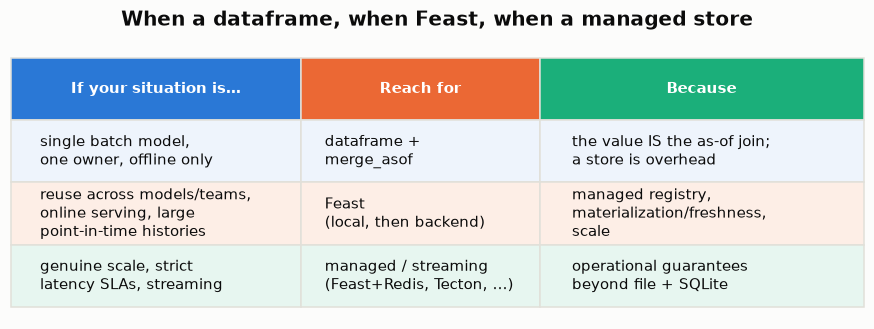

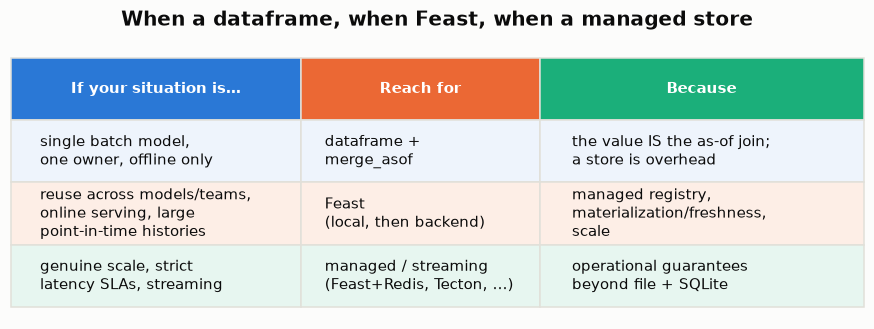

In [3]:
rows = [
    ["single batch model,\none owner, offline only", "dataframe +\nmerge_asof",
     "the value IS the as-of join;\na store is overhead"],
    ["reuse across models/teams,\nonline serving, large\npoint-in-time histories", "Feast\n(local, then backend)",
     "managed registry,\nmaterialization/freshness,\nscale"],
    ["genuine scale, strict\nlatency SLAs, streaming", "managed / streaming\n(Feast+Redis, Tecton, ...)",
     "operational guarantees\nbeyond file + SQLite"],
]
col_labels = ["If your situation is…", "Reach for", "Because"]
cell_colors = [[c, c, c] for c in ["#eef4fc", "#fdeee6", "#e7f6f0"]]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axis("off")
table = ax.table(cellText=rows, colLabels=col_labels, cellColours=cell_colors,
                 colColours=[BLUE, ORANGE, AQUA], cellLoc="left", loc="center",
                 colWidths=[0.34, 0.28, 0.38])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 3.4)
for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor(GRID)
    if r == 0:
        cell.set_text_props(color="white", fontweight="bold")
    else:
        cell.set_text_props(color=TEXT_PRIMARY)
ax.set_title("When a dataframe, when Feast, when a managed store", fontweight="bold", pad=14)
save_figure(fig, "06_decision_matrix")
fig

## The rule that outranks the tool choice

> **You may not need a feature store, but you always need point-in-time correctness and
> train/serve consistency. If you skip the store, do not skip the discipline.**

Everything we measured is a consequence of that rule. The chart below recaps the payoff in one
place: the AUC the naive join *overstated* offline, how far it *collapsed* on the true future,
and the accuracy a silent skew *cost* — all avoidable with the two disciplines, with or without
the tool.

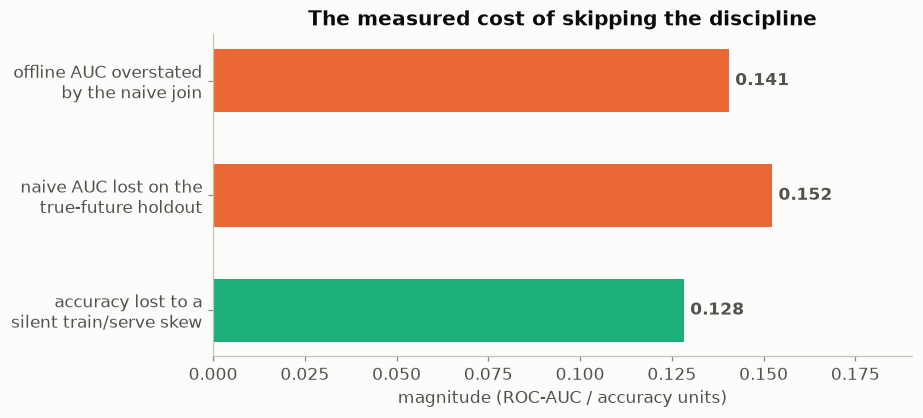

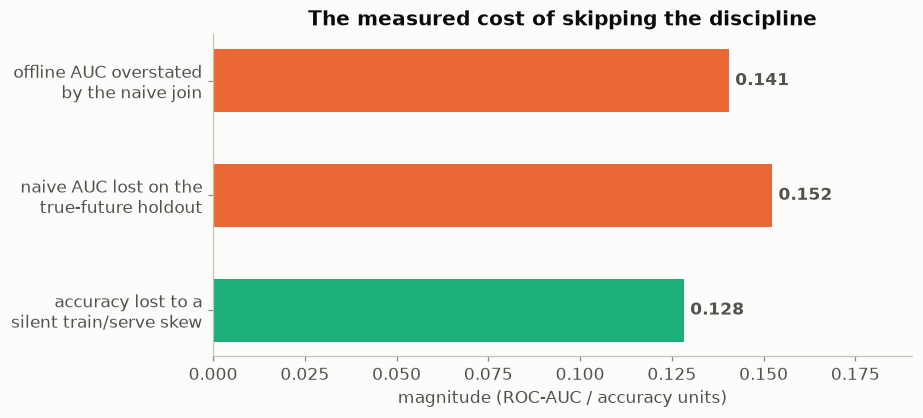

In [4]:
leak = run_leakage_experiment(ds, settings)
skew = run_skew_experiment(ds, settings)

labels = [
    "offline AUC overstated\nby the naive join",
    "naive AUC lost on the\ntrue-future holdout",
    "accuracy lost to a\nsilent train/serve skew",
]
values = [leak.inflation, leak.collapse, skew.accuracy_slip]
colors = [ORANGE, ORANGE, AQUA]
y = np.arange(len(labels))[::-1]

fig, ax = plt.subplots(figsize=(8.2, 3.8))
bars = ax.barh(y, values, color=colors, height=0.55)
ax.bar_label(bars, fmt="%.3f", padding=4, fontweight="bold", color=TEXT_SECONDARY)
ax.set_yticks(y, labels)
ax.set_xlim(0, max(values) * 1.25)
ax.set_xlabel("magnitude (ROC-AUC / accuracy units)")
ax.set_title("The measured cost of skipping the discipline")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
save_figure(fig, "06_payoff")
fig

In [5]:
payload = {
    "decision": [
        {"situation": "single batch model, one owner, offline only",
         "use": "dataframe + merge_asof",
         "why": "the value is the as-of join; a store is overhead"},
        {"situation": "reuse across models/teams, online serving, large point-in-time histories",
         "use": "Feast (local, then a backend)",
         "why": "managed registry, materialization/freshness, scale"},
        {"situation": "genuine scale, strict latency SLAs, streaming features",
         "use": "managed / streaming store (Feast+Redis, Tecton, SageMaker FS)",
         "why": "operational guarantees beyond file + SQLite"},
    ],
    "outranking_rule": (
        "You may not need a feature store, but you always need point-in-time correctness and "
        "train/serve consistency. If you skip the store, do not skip the discipline."
    ),
    "measured_payoff": {
        "offline_auc_inflation": leak.inflation,
        "future_auc_collapse": leak.collapse,
        "skew_accuracy_slip": skew.accuracy_slip,
    },
    "summary_table": summary.to_dict(orient="records"),
}
print(save_json(payload, "06_decision"))
payload["measured_payoff"]

/workspaces/feature_store_101/outputs/json/06_decision.json


{'offline_auc_inflation': 0.14059021214030676,
 'future_auc_collapse': 0.15237152029100376,
 'skew_accuracy_slip': 0.1283333333333333}

## That's the series

You built a feature store from first principles, planted a leak you could measure, watched it
collapse on the future, exposed a silent train/serve skew, and saw Feast do the same thing
locally. You can now tell when a dataframe is enough and when the tool earns its keep — and you
will never again skip the two disciplines that outrank the choice.

*Related in this series: [`cv_arena`](https://github.com/Dima806/cv_arena) ·
[`feature_engineering_arena`](https://github.com/Dima806/feature_engineering_arena) ·
[`model_drift_detector`](https://github.com/Dima806/model_drift_detector) ·
[`timeseries_101`](https://github.com/Dima806/timeseries_101) ·
[`metrics_101`](https://github.com/Dima806/metrics_101) · **feature_store_101**.*